In [ ]:

from google.colab import files
import zipfile
import os

# 1. Importer le dataset ZIP depuis l'ordinateur
uploaded = files.upload()

# 2. Récupérer le nom du fichier ZIP
nom_zip = next(iter(uploaded.keys()))

# 3. Créer le dossier de destination
dossier_dataset = "/content/dataset"
os.makedirs(dossier_dataset, exist_ok=True)

# 4. Extraire le contenu du ZIP
with zipfile.ZipFile(nom_zip, 'r') as zip_ref:
    zip_ref.extractall(dossier_dataset)

print("Dataset chargé et extrait avec succès !")
print("Emplacement :", dossier_dataset)


Saving dataset (2).zip to dataset (2).zip
Dataset chargé et extrait avec succès !
Emplacement : /content/dataset


In [ ]:

import os
from PIL import Image
from collections import Counter

# Chemin du dataset déjà chargé
dossier_dataset = "/content/dataset/dataset"

# Les quatre classes
classes = ["bananes", "orange", "pomme", "tamaraillo"]

extensions_valides = (".jpg", ".jpeg", ".png", ".webp")
total_images = 0
images_illisibles = []

print("=== VÉRIFICATION DU DATASET ===\n")

for classe in classes:
    chemin_classe = os.path.join(dossier_dataset, classe)

    if not os.path.isdir(chemin_classe):
        print(f"ERREUR : dossier absent -> {classe}")
        continue

    fichiers = [
        f for f in os.listdir(chemin_classe)
        if f.lower().endswith(extensions_valides)
    ]

    total_images += len(fichiers)
    formats = Counter()

    for fichier in fichiers:
        chemin_image = os.path.join(chemin_classe, fichier)
        formats[os.path.splitext(fichier)[1].lower()] += 1

        try:
            with Image.open(chemin_image) as image:
                image.verify()
        except Exception:
            images_illisibles.append(chemin_image)

    print(f"{classe} : {len(fichiers)} images")
    print(f"  Formats : {dict(formats)}")

print("\n=== BILAN ===")
print("Total des images :", total_images)
print("Images illisibles :", len(images_illisibles))

if images_illisibles:
    print("\nExemples d'images à vérifier :")
    for chemin in images_illisibles[:10]:
        print(chemin)


=== VÉRIFICATION DU DATASET ===

bananes : 100 images
  Formats : {'.jpg': 100}
orange : 100 images
  Formats : {'.jpg': 100}
pomme : 100 images
  Formats : {'.jpg': 100}
tamaraillo : 100 images
  Formats : {'.jpg': 100}

=== BILAN ===
Total des images : 400
Images illisibles : 0


In [ ]:

import os
import random
import shutil

# Reproductibilité des résultats
random.seed(42)

source = "/content/dataset/dataset"
destination = "/content/fruits_split"

classes = ["bananes", "orange", "pomme", "tamaraillo"]
extensions = (".jpg", ".jpeg", ".png", ".webp")

# Éviter de mélanger deux fois les données
if os.path.exists(destination):
    raise FileExistsError(
        "Le dossier fruits_split existe déjà. "
        "Ne relance pas la division avant de vérifier son contenu."
    )

for classe in classes:
    fichiers = [
        f for f in os.listdir(os.path.join(source, classe))
        if f.lower().endswith(extensions)
    ]

    random.shuffle(fichiers)

    train = fichiers[:70]
    val = fichiers[70:85]
    test = fichiers[85:100]

    for nom_split, liste in [
        ("train", train),
        ("val", val),
        ("test", test)
    ]:
        dossier = os.path.join(destination, nom_split, classe)
        os.makedirs(dossier, exist_ok=True)

        for fichier in liste:
            shutil.copy2(
                os.path.join(source, classe, fichier),
                os.path.join(dossier, fichier)
            )

print("Division terminée !\n")

for split in ["train", "val", "test"]:
    print(f"\n{split.upper()} :")
    total = 0

    for classe in classes:
        chemin = os.path.join(destination, split, classe)
        nombre = len(os.listdir(chemin))
        total += nombre
        print(f"  {classe} : {nombre}")

    print(f"  Total : {total}")

print("\nDataset préparé dans :", destination)


Division terminée !


TRAIN :
  bananes : 70
  orange : 70
  pomme : 70
  tamaraillo : 70
  Total : 280

VAL :
  bananes : 15
  orange : 15
  pomme : 15
  tamaraillo : 15
  Total : 60

TEST :
  bananes : 15
  orange : 15
  pomme : 15
  tamaraillo : 15
  Total : 60

Dataset préparé dans : /content/fruits_split


In [ ]:

import os
import numpy as np

from PIL import Image
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix
from sklearn.preprocessing import normalize

# Chemins des données
base_dir = "/content/fruits_split"
classes = ["bananes", "orange", "pomme", "tamaraillo"]

# Extraire un histogramme RGB de chaque image
def extraire_histogramme(chemin, taille=(128, 128)):
    image = Image.open(chemin).convert("RGB")
    image = image.resize(taille)

    tableau = np.array(image)
    caracteristiques = []

    for canal in range(3):
        hist, _ = np.histogram(
            tableau[:, :, canal],
            bins=32,
            range=(0, 256)
        )
        caracteristiques.extend(hist)

    # Normaliser les histogrammes
    caracteristiques = np.array(caracteristiques, dtype=np.float32)
    caracteristiques /= caracteristiques.sum()

    return caracteristiques


def charger_donnees(split):
    X, y = [], []

    for classe in classes:
        dossier = os.path.join(base_dir, split, classe)

        for nom in sorted(os.listdir(dossier)):
            if nom.lower().endswith((".jpg", ".jpeg", ".png", ".webp")):
                chemin = os.path.join(dossier, nom)
                X.append(extraire_histogramme(chemin))
                y.append(classe)

    return np.array(X), np.array(y)


X_train, y_train = charger_donnees("train")
X_val, y_val = charger_donnees("val")

print("Caractéristiques d'entraînement :", X_train.shape)
print("Labels d'entraînement :", y_train.shape)
print("Caractéristiques de validation :", X_val.shape)
print("Labels de validation :", y_val.shape)


Caractéristiques d'entraînement : (280, 96)
Labels d'entraînement : (280,)
Caractéristiques de validation : (60, 96)
Labels de validation : (60,)


In [ ]:

# Créer le modèle k-NN avec 3 voisins
modele_knn = KNeighborsClassifier(n_neighbors=3)

# Entraîner le modèle
modele_knn.fit(X_train, y_train)

# Prédire les classes sur la validation
predictions = modele_knn.predict(X_val)

# Calculer les performances
accuracy = accuracy_score(y_val, predictions)

print(f"Accuracy de validation : {accuracy:.2%}")
print("\nRapport de classification :")
print(classification_report(
    y_val,
    predictions,
    labels=classes,
    zero_division=0
))

print("Matrice de confusion :")
print(confusion_matrix(y_val, predictions, labels=classes))


Accuracy de validation : 63.33%

Rapport de classification :
              precision    recall  f1-score   support

     bananes       0.50      0.93      0.65        15
      orange       0.79      0.73      0.76        15
       pomme       0.86      0.40      0.55        15
  tamaraillo       0.64      0.47      0.54        15

    accuracy                           0.63        60
   macro avg       0.69      0.63      0.62        60
weighted avg       0.69      0.63      0.62        60

Matrice de confusion :
[[14  0  0  1]
 [ 3 11  0  1]
 [ 6  1  6  2]
 [ 5  2  1  7]]


In [ ]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix

# Construire le modèle SVM
modele_svm = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", C=1.0, gamma="scale")
)

# Entraîner sur les caractéristiques de couleur
modele_svm.fit(X_train, y_train)

# Évaluer sur la validation
pred_svm = modele_svm.predict(X_val)

print(f"Accuracy SVM : {accuracy_score(y_val, pred_svm):.2%}")

print("\nRapport de classification :")
print(classification_report(
    y_val, pred_svm,
    labels=classes,
    zero_division=0
))

print("Matrice de confusion :")
print(confusion_matrix(y_val, pred_svm, labels=classes))


Accuracy SVM : 68.33%

Rapport de classification :
              precision    recall  f1-score   support

     bananes       0.60      0.80      0.69        15
      orange       0.86      0.80      0.83        15
       pomme       0.75      0.60      0.67        15
  tamaraillo       0.57      0.53      0.55        15

    accuracy                           0.68        60
   macro avg       0.69      0.68      0.68        60
weighted avg       0.69      0.68      0.68        60

Matrice de confusion :
[[12  0  0  3]
 [ 1 12  1  1]
 [ 3  1  9  2]
 [ 4  1  2  8]]


In [ ]:

import os
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

# Vérifier le matériel disponible
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Matériel utilisé :", device)

# Dossiers préparés précédemment
base_dir = "/content/fruits_split"

# Redimensionner les images et les convertir en tenseurs
transformation = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor()
])

train_dataset = datasets.ImageFolder(
    os.path.join(base_dir, "train"),
    transform=transformation
)

val_dataset = datasets.ImageFolder(
    os.path.join(base_dir, "val"),
    transform=transformation
)

# Garder le même ordre des classes
print("Classes :", train_dataset.classes)
print("Images d'entraînement :", len(train_dataset))
print("Images de validation :", len(val_dataset))

train_loader = DataLoader(
    train_dataset, batch_size=16, shuffle=True
)

val_loader = DataLoader(
    val_dataset, batch_size=16, shuffle=False
)

# Vérifier la forme d'un lot d'images
images, labels = next(iter(train_loader))
print("Forme des images :", images.shape)
print("Forme des étiquettes :", labels.shape)


Matériel utilisé : cpu
Classes : ['bananes', 'orange', 'pomme', 'tamaraillo']
Images d'entraînement : 280
Images de validation : 60
Forme des images : torch.Size([16, 3, 128, 128])
Forme des étiquettes : torch.Size([16])


In [ ]:

class CNNFruits(nn.Module):
    def __init__(self, nombre_classes=4):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((4, 4))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 4 * 4, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, nombre_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


modele_cnn = CNNFruits(nombre_classes=4).to(device)

print(modele_cnn)


CNNFruits(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): AdaptiveAvgPool2d(output_size=(4, 4))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1024, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=4, bias=True)
  )
)


In [ ]:
print("Classes :", train_dataset.classes)
print("Images d'entraînement :", len(train_dataset))
print("Images de validation :", len(val_dataset))
print("Appareil utilisé :", device)

Classes : ['bananes', 'orange', 'pomme', 'tamaraillo']
Images d'entraînement : 280
Images de validation : 60
Appareil utilisé : cpu


In [ ]:

import torch
import torch.nn as nn
import copy

# Vérifier que le modèle CNN existe
modele_cnn = modele_cnn.to(device)

# Fonction de perte et optimiseur
critere = nn.CrossEntropyLoss()
optimiseur = torch.optim.Adam(
    modele_cnn.parameters(),
    lr=0.001
)

# Paramètres de l'entraînement
nombre_epoques = 10

historique = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

meilleure_accuracy = 0.0
meilleurs_poids = copy.deepcopy(modele_cnn.state_dict())

for epoque in range(nombre_epoques):

    # ----- Entraînement -----
    modele_cnn.train()
    perte_train = 0.0
    correct_train = 0
    total_train = 0

    for images, etiquettes in train_loader:
        images = images.to(device)
        etiquettes = etiquettes.to(device)

        optimiseur.zero_grad()
        sorties = modele_cnn(images)
        perte = critere(sorties, etiquettes)
        perte.backward()
        optimiseur.step()

        perte_train += perte.item() * images.size(0)
        predictions = sorties.argmax(dim=1)
        correct_train += (predictions == etiquettes).sum().item()
        total_train += etiquettes.size(0)

    perte_train /= total_train
    precision_train = correct_train / total_train

    # ----- Validation -----
    modele_cnn.eval()
    perte_val = 0.0
    correct_val = 0
    total_val = 0

    with torch.no_grad():
        for images, etiquettes in val_loader:
            images = images.to(device)
            etiquettes = etiquettes.to(device)

            sorties = modele_cnn(images)
            perte = critere(sorties, etiquettes)

            perte_val += perte.item() * images.size(0)
            predictions = sorties.argmax(dim=1)
            correct_val += (predictions == etiquettes).sum().item()
            total_val += etiquettes.size(0)

    perte_val /= total_val
    precision_val = correct_val / total_val

    # Enregistrer les résultats
    historique["train_loss"].append(perte_train)
    historique["val_loss"].append(perte_val)
    historique["train_acc"].append(precision_train)
    historique["val_acc"].append(precision_val)

    # Conserver le meilleur modèle de validation
    if precision_val > meilleure_accuracy:
        meilleure_accuracy = precision_val
        meilleurs_poids = copy.deepcopy(modele_cnn.state_dict())

    print(
        f"Époque {epoque + 1}/{nombre_epoques} | "
        f"Loss train: {perte_train:.4f} | "
        f"Accuracy train: {precision_train*100:.2f}% | "
        f"Loss val: {perte_val:.4f} | "
        f"Accuracy val: {precision_val*100:.2f}%"
    )

# Restaurer les meilleurs poids
modele_cnn.load_state_dict(meilleurs_poids)

print("\nEntraînement terminé.")
print(f"Meilleure précision de validation : {meilleure_accuracy*100:.2f}%")


Époque 1/10 | Loss train: 1.3920 | Accuracy train: 21.43% | Loss val: 1.3848 | Accuracy val: 18.33%
Époque 2/10 | Loss train: 1.3857 | Accuracy train: 22.14% | Loss val: 1.3821 | Accuracy val: 21.67%
Époque 3/10 | Loss train: 1.3765 | Accuracy train: 25.36% | Loss val: 1.3540 | Accuracy val: 36.67%
Époque 4/10 | Loss train: 1.3617 | Accuracy train: 32.14% | Loss val: 1.3224 | Accuracy val: 36.67%
Époque 5/10 | Loss train: 1.3318 | Accuracy train: 34.29% | Loss val: 1.2790 | Accuracy val: 40.00%
Époque 6/10 | Loss train: 1.2748 | Accuracy train: 42.14% | Loss val: 1.2463 | Accuracy val: 46.67%
Époque 7/10 | Loss train: 1.1551 | Accuracy train: 45.00% | Loss val: 1.0854 | Accuracy val: 50.00%
Époque 8/10 | Loss train: 1.0426 | Accuracy train: 56.07% | Loss val: 0.9191 | Accuracy val: 55.00%
Époque 9/10 | Loss train: 0.9486 | Accuracy train: 57.14% | Loss val: 0.8599 | Accuracy val: 55.00%
Époque 10/10 | Loss train: 0.8474 | Accuracy train: 63.21% | Loss val: 0.9114 | Accuracy val: 53.33%

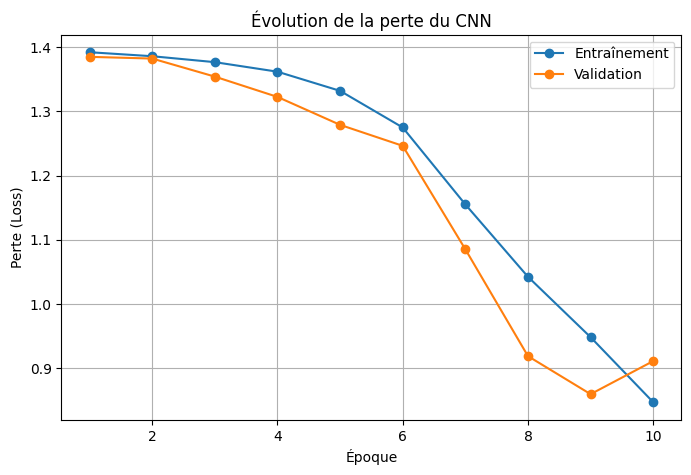

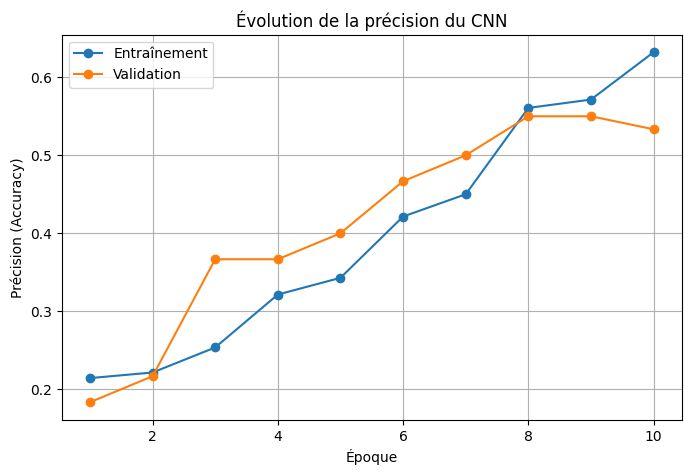

In [ ]:

import matplotlib.pyplot as plt

epoques = range(1, len(historique["train_loss"]) + 1)

# 1. Courbe des pertes
plt.figure(figsize=(8, 5))
plt.plot(epoques, historique["train_loss"], marker="o", label="Entraînement")
plt.plot(epoques, historique["val_loss"], marker="o", label="Validation")
plt.xlabel("Époque")
plt.ylabel("Perte (Loss)")
plt.title("Évolution de la perte du CNN")
plt.legend()
plt.grid(True)
plt.show()

# 2. Courbe des précisions
plt.figure(figsize=(8, 5))
plt.plot(epoques, historique["train_acc"], marker="o", label="Entraînement")
plt.plot(epoques, historique["val_acc"], marker="o", label="Validation")
plt.xlabel("Époque")
plt.ylabel("Précision (Accuracy)")
plt.title("Évolution de la précision du CNN")
plt.legend()
plt.grid(True)
plt.show()


Précision du CNN sur la validation : 55.00%


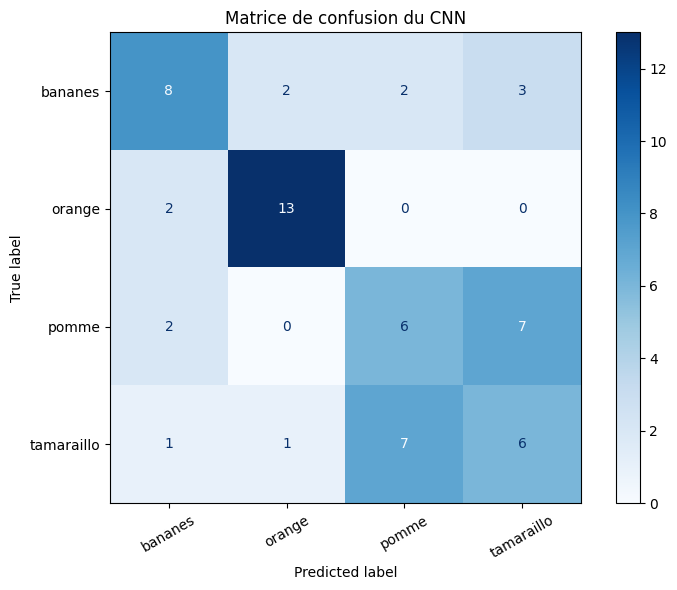


Rapport de classification :
              precision    recall  f1-score   support

     bananes       0.62      0.53      0.57        15
      orange       0.81      0.87      0.84        15
       pomme       0.40      0.40      0.40        15
  tamaraillo       0.38      0.40      0.39        15

    accuracy                           0.55        60
   macro avg       0.55      0.55      0.55        60
weighted avg       0.55      0.55      0.55        60



In [ ]:

import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, ConfusionMatrixDisplay

# Mettre le modèle en mode évaluation
modele_cnn.eval()

y_true = []
y_pred = []

# Prédictions sur les 60 images de validation
with torch.no_grad():
    for images, etiquettes in val_loader:
        images = images.to(device)

        sorties = modele_cnn(images)
        predictions = sorties.argmax(dim=1).cpu().numpy()

        y_pred.extend(predictions)
        y_true.extend(etiquettes.numpy())

# Noms des classes
noms_classes = val_dataset.classes

# Précision globale
accuracy = accuracy_score(y_true, y_pred)
print(f"Précision du CNN sur la validation : {accuracy * 100:.2f}%")

# Matrice de confusion
matrice = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(noms_classes)))
)

affichage = ConfusionMatrixDisplay(
    confusion_matrix=matrice,
    display_labels=noms_classes
)

fig, ax = plt.subplots(figsize=(8, 6))
affichage.plot(ax=ax, cmap="Blues", values_format="d")
plt.title("Matrice de confusion du CNN")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Rapport détaillé par classe
print("\nRapport de classification :")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(noms_classes))),
    target_names=noms_classes,
    zero_division=0
))


In [ ]:

from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Transformations appliquées uniquement à l'entraînement
transformations_train = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15
    ),
    transforms.ToTensor()
])

# Validation sans augmentation aléatoire
transformations_val = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor()
])

# Charger les jeux de données
base_dir = "/content/fruits_split"

train_dataset_aug = datasets.ImageFolder(
    root=f"{base_dir}/train",
    transform=transformations_train
)

val_dataset_aug = datasets.ImageFolder(
    root=f"{base_dir}/val",
    transform=transformations_val
)

# Créer les chargeurs de données
train_loader_aug = DataLoader(
    train_dataset_aug,
    batch_size=16,
    shuffle=True
)

val_loader_aug = DataLoader(
    val_dataset_aug,
    batch_size=16,
    shuffle=False
)

print("Classes :", train_dataset_aug.classes)
print("Images d'entraînement :", len(train_dataset_aug))
print("Images de validation :", len(val_dataset_aug))
print("Augmentation des données activée.")


Classes : ['bananes', 'orange', 'pomme', 'tamaraillo']
Images d'entraînement : 280
Images de validation : 60
Augmentation des données activée.


In [ ]:

import torch
import torch.nn as nn
from torchvision import models

# Choisir le processeur disponible
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Appareil utilisé :", device)

# Charger ResNet-18 avec des poids préentraînés
poids = models.ResNet18_Weights.DEFAULT
resnet18 = models.resnet18(weights=poids)

# Remplacer la dernière couche pour nos 4 classes
nombre_caracteristiques = resnet18.fc.in_features
resnet18.fc = nn.Linear(nombre_caracteristiques, 4)

# Envoyer le modèle sur le processeur
resnet18 = resnet18.to(device)

# Afficher les classes et la dernière couche
print("Classes :", train_dataset_aug.classes)
print("Nouvelle couche de sortie :", resnet18.fc)
print("ResNet-18 prêt pour le transfert d'apprentissage.")


Appareil utilisé : cpu
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 165MB/s]


Classes : ['bananes', 'orange', 'pomme', 'tamaraillo']
Nouvelle couche de sortie : Linear(in_features=512, out_features=4, bias=True)
ResNet-18 prêt pour le transfert d'apprentissage.


In [ ]:
import torch
import torch.nn as nn

# 1. Geler les couches préentraînées de ResNet-18
# On parcourt tous les paramètres du modèle et on désactive le calcul des gradients (requires_grad = False).
# Cela permet de conserver les fonctionnalités visuelles déjà apprises par le modèle sur ImageNet.
for parametre in resnet18.parameters():
    parametre.requires_grad = False

# 2. Autoriser l'apprentissage uniquement pour la dernière couche (la couche de classification 'fc')
# On réactive le calcul des gradients uniquement pour les poids et biais de la nouvelle couche linéaire.
# C'est cette couche qui va apprendre à classifier nos 4 types de fruits.
for parametre in resnet18.fc.parameters():
    parametre.requires_grad = True

# 3. Définir la fonction de perte (Loss Function)
# On utilise la perte d'entropie croisée (CrossEntropyLoss), parfaitement adaptée pour la classification multi-classe.
critere_resnet = nn.CrossEntropyLoss()

# 4. Configurer l'optimiseur (Adam)
# On utilise l'optimiseur Adam en lui passant UNIQUEMENT les paramètres de la couche 'fc'.
# Ainsi, aucun autre poids du réseau ne sera modifié pendant cette phase d'entraînement.
optimiseur_resnet = torch.optim.Adam(
    resnet18.fc.parameters(),
    lr=0.001
)

# 5. Vérifier et afficher le nombre de paramètres
# On calcule le nombre de paramètres qui vont réellement être entraînés (qui requièrent un gradient).
parametres_entrainables = sum(
    p.numel() for p in resnet18.parameters()
    if p.requires_grad
)

# On calcule le nombre total de paramètres du modèle pour comparer.
parametres_total = sum(
    p.numel() for p in resnet18.parameters()
)

print("Paramètres entraînables :", parametres_entrainables)
print("Paramètres totaux :", parametres_total)
print("Les couches préentraînées sont gelées.")
print("La dernière couche est prête à être entraînée.")

Paramètres entraînables : 2052
Paramètres totaux : 11178564
Les couches préentraînées sont gelées.
La dernière couche est prête à être entraînée.


In [ ]:

import copy
import torch

nombre_epoques_resnet = 5

historique_resnet = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

meilleure_accuracy_resnet = 0.0
meilleurs_poids_resnet = copy.deepcopy(resnet18.state_dict())

for epoque in range(nombre_epoques_resnet):

    # ----- ENTRAÎNEMENT -----
    resnet18.train()

    # Garder les couches préentraînées en mode évaluation
    # pour stabiliser leurs couches BatchNorm
    for nom, module in resnet18.named_children():
        if nom != "fc":
            module.eval()

    perte_train = 0.0
    correct_train = 0
    total_train = 0

    for images, etiquettes in train_loader_aug:
        images = images.to(device)
        etiquettes = etiquettes.to(device)

        optimiseur_resnet.zero_grad()

        sorties = resnet18(images)
        perte = critere_resnet(sorties, etiquettes)

        perte.backward()
        optimiseur_resnet.step()

        perte_train += perte.item() * images.size(0)
        predictions = sorties.argmax(dim=1)
        correct_train += (predictions == etiquettes).sum().item()
        total_train += etiquettes.size(0)

    perte_train /= total_train
    precision_train = correct_train / total_train

    # ----- VALIDATION -----
    resnet18.eval()

    perte_val = 0.0
    correct_val = 0
    total_val = 0

    with torch.no_grad():
        for images, etiquettes in val_loader_aug:
            images = images.to(device)
            etiquettes = etiquettes.to(device)

            sorties = resnet18(images)
            perte = critere_resnet(sorties, etiquettes)

            perte_val += perte.item() * images.size(0)
            predictions = sorties.argmax(dim=1)
            correct_val += (predictions == etiquettes).sum().item()
            total_val += etiquettes.size(0)

    perte_val /= total_val
    precision_val = correct_val / total_val

    historique_resnet["train_loss"].append(perte_train)
    historique_resnet["val_loss"].append(perte_val)
    historique_resnet["train_acc"].append(precision_train)
    historique_resnet["val_acc"].append(precision_val)

    if precision_val > meilleure_accuracy_resnet:
        meilleure_accuracy_resnet = precision_val
        meilleurs_poids_resnet = copy.deepcopy(resnet18.state_dict())

    print(
        f"Époque {epoque + 1}/{nombre_epoques_resnet} | "
        f"Loss train : {perte_train:.4f} | "
        f"Accuracy train : {precision_train*100:.2f}% | "
        f"Loss val : {perte_val:.4f} | "
        f"Accuracy val : {precision_val*100:.2f}%"
    )

# Restaurer les poids obtenant la meilleure précision de validation
resnet18.load_state_dict(meilleurs_poids_resnet)

print("\nEntraînement terminé.")
print(
    f"Meilleure précision de validation : "
    f"{meilleure_accuracy_resnet*100:.2f}%"
)


Époque 1/5 | Loss train : 1.0984 | Accuracy train : 54.64% | Loss val : 0.6490 | Accuracy val : 81.67%
Époque 2/5 | Loss train : 0.6015 | Accuracy train : 80.00% | Loss val : 0.5094 | Accuracy val : 86.67%
Époque 3/5 | Loss train : 0.4279 | Accuracy train : 87.86% | Loss val : 0.4189 | Accuracy val : 90.00%
Époque 4/5 | Loss train : 0.3551 | Accuracy train : 91.43% | Loss val : 0.3952 | Accuracy val : 90.00%
Époque 5/5 | Loss train : 0.3005 | Accuracy train : 93.57% | Loss val : 0.3670 | Accuracy val : 90.00%

Entraînement terminé.
Meilleure précision de validation : 90.00%


Précision ResNet-18 sur la validation : 90.00%


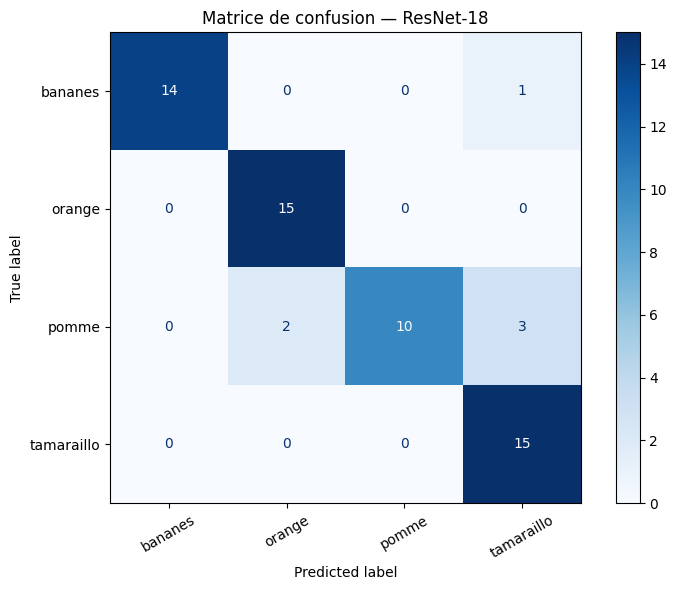


Rapport de classification :
              precision    recall  f1-score   support

     bananes       1.00      0.93      0.97        15
      orange       0.88      1.00      0.94        15
       pomme       1.00      0.67      0.80        15
  tamaraillo       0.79      1.00      0.88        15

    accuracy                           0.90        60
   macro avg       0.92      0.90      0.90        60
weighted avg       0.92      0.90      0.90        60



In [ ]:

import torch
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    ConfusionMatrixDisplay
)

resnet18.eval()

y_true_resnet = []
y_pred_resnet = []

with torch.no_grad():
    for images, etiquettes in val_loader_aug:
        images = images.to(device)

        sorties = resnet18(images)
        predictions = sorties.argmax(dim=1).cpu().tolist()

        y_pred_resnet.extend(predictions)
        y_true_resnet.extend(etiquettes.tolist())

noms_classes = val_dataset_aug.classes

accuracy_resnet = accuracy_score(
    y_true_resnet,
    y_pred_resnet
)

print(
    f"Précision ResNet-18 sur la validation : "
    f"{accuracy_resnet * 100:.2f}%"
)

matrice_resnet = confusion_matrix(
    y_true_resnet,
    y_pred_resnet,
    labels=list(range(len(noms_classes)))
)

fig, ax = plt.subplots(figsize=(8, 6))

affichage = ConfusionMatrixDisplay(
    confusion_matrix=matrice_resnet,
    display_labels=noms_classes
)

affichage.plot(
    ax=ax,
    cmap="Blues",
    values_format="d"
)

plt.title("Matrice de confusion — ResNet-18")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

print("\nRapport de classification :")
print(classification_report(
    y_true_resnet,
    y_pred_resnet,
    labels=list(range(len(noms_classes))),
    target_names=noms_classes,
    zero_division=0
))


Nombre d'images mal classées : 6
Nombre d'images correctement classées : 54


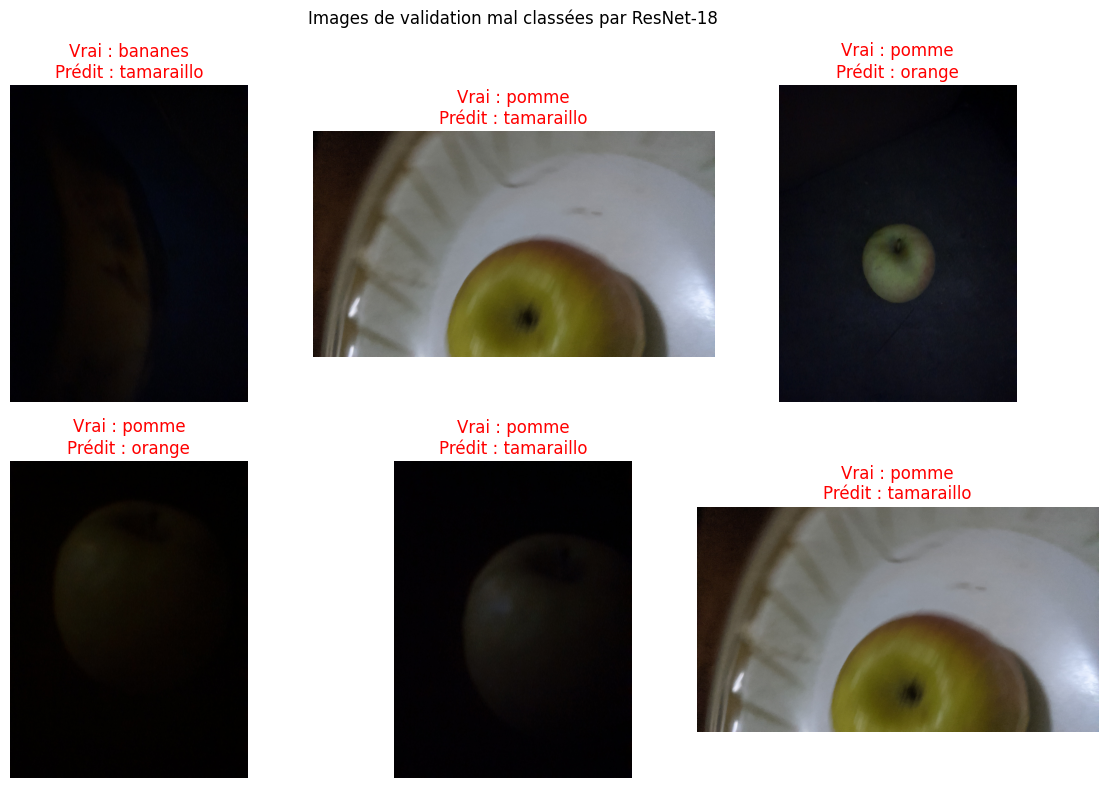

In [ ]:

import torch
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

resnet18.eval()

noms_classes = val_dataset_aug.classes
images_fausses = []

# Parcourir les images de validation
with torch.no_grad():
    for indice in range(len(val_dataset_aug)):
        image, vraie_classe = val_dataset_aug[indice]

        entree = image.unsqueeze(0).to(device)
        sortie = resnet18(entree)
        prediction = sortie.argmax(dim=1).item()

        # Conserver uniquement les erreurs
        if prediction != vraie_classe:
            chemin, etiquette = val_dataset_aug.samples[indice]

            images_fausses.append({
                "chemin": chemin,
                "vraie_classe": vraie_classe,
                "prediction": prediction
            })

print("Nombre d'images mal classées :", len(images_fausses))
print("Nombre d'images correctement classées :",
      len(val_dataset_aug) - len(images_fausses))

# Afficher les images incorrectement prédites
if len(images_fausses) > 0:
    colonnes = 3
    lignes = (len(images_fausses) + colonnes - 1) // colonnes

    fig, axes = plt.subplots(
        lignes, colonnes,
        figsize=(12, 4 * lignes)
    )

    axes = np.array(axes, dtype=object).reshape(-1)

    for ax, erreur in zip(axes, images_fausses):
        photo = Image.open(erreur["chemin"]).convert("RGB")

        ax.imshow(photo)
        ax.set_title(
            f"Vrai : {noms_classes[erreur['vraie_classe']]}\n"
            f"Prédit : {noms_classes[erreur['prediction']]}",
            color="red"
        )
        ax.axis("off")

    # Masquer les cases inutilisées
    for ax in axes[len(images_fausses):]:
        ax.axis("off")

    plt.suptitle("Images de validation mal classées par ResNet-18")
    plt.tight_layout()
    plt.show()
else:
    print("Aucune erreur de classification sur la validation.")


In [ ]:

import torch
import torch.nn as nn

# Geler d'abord tous les paramètres
for parametre in resnet18.parameters():
    parametre.requires_grad = False

# Débloquer les dernières couches pour l'adaptation
for parametre in resnet18.layer4.parameters():
    parametre.requires_grad = True

for parametre in resnet18.fc.parameters():
    parametre.requires_grad = True

# Fonction de perte
critere_resnet = nn.CrossEntropyLoss()

# Taux d'apprentissage faible pour le fine-tuning
optimiseur_finetuning = torch.optim.Adam([
    {"params": resnet18.layer4.parameters(), "lr": 0.0001},
    {"params": resnet18.fc.parameters(), "lr": 0.0005}
])

# Vérifier le nombre de paramètres entraînables
entrainables = sum(
    p.numel() for p in resnet18.parameters()
    if p.requires_grad
)

print("Paramètres entraînables :", entrainables)
print("Fine-tuning de layer4 et fc activé.")


Paramètres entraînables : 8395780
Fine-tuning de layer4 et fc activé.


In [ ]:

import copy
import torch

epoques_finetuning = 5

historique_finetuning = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

# Sauvegarder le modèle actuel comme référence
meilleure_accuracy_finetuning = 0.0
meilleurs_poids_finetuning = copy.deepcopy(resnet18.state_dict())

for epoque in range(epoques_finetuning):

    # ----- ENTRAÎNEMENT -----
    resnet18.train()

    # Garder les premières couches en mode évaluation
    resnet18.conv1.eval()
    resnet18.bn1.eval()
    resnet18.layer1.eval()
    resnet18.layer2.eval()
    resnet18.layer3.eval()

    perte_train = 0.0
    correct_train = 0
    total_train = 0

    for images, etiquettes in train_loader_aug:
        images = images.to(device)
        etiquettes = etiquettes.to(device)

        optimiseur_finetuning.zero_grad()
        sorties = resnet18(images)
        perte = critere_resnet(sorties, etiquettes)

        perte.backward()
        optimiseur_finetuning.step()

        perte_train += perte.item() * images.size(0)
        predictions = sorties.argmax(dim=1)
        correct_train += (predictions == etiquettes).sum().item()
        total_train += etiquettes.size(0)

    perte_train /= total_train
    accuracy_train = correct_train / total_train

    # ----- VALIDATION -----
    resnet18.eval()
    perte_val = 0.0
    correct_val = 0
    total_val = 0

    with torch.no_grad():
        for images, etiquettes in val_loader_aug:
            images = images.to(device)
            etiquettes = etiquettes.to(device)

            sorties = resnet18(images)
            perte = critere_resnet(sorties, etiquettes)

            perte_val += perte.item() * images.size(0)
            predictions = sorties.argmax(dim=1)
            correct_val += (predictions == etiquettes).sum().item()
            total_val += etiquettes.size(0)

    perte_val /= total_val
    accuracy_val = correct_val / total_val

    historique_finetuning["train_loss"].append(perte_train)
    historique_finetuning["val_loss"].append(perte_val)
    historique_finetuning["train_acc"].append(accuracy_train)
    historique_finetuning["val_acc"].append(accuracy_val)

    # Conserver le meilleur résultat de cette phase
    if accuracy_val > meilleure_accuracy_finetuning:
        meilleure_accuracy_finetuning = accuracy_val
        meilleurs_poids_finetuning = copy.deepcopy(
            resnet18.state_dict()
        )

    print(
        f"Époque {epoque + 1}/{epoques_finetuning} | "
        f"Loss train : {perte_train:.4f} | "
        f"Accuracy train : {accuracy_train*100:.2f}% | "
        f"Loss val : {perte_val:.4f} | "
        f"Accuracy val : {accuracy_val*100:.2f}%"
    )

# Restaurer les meilleurs poids de cette phase
resnet18.load_state_dict(meilleurs_poids_finetuning)

print("\nFine-tuning terminé.")
print(
    "Meilleure précision de validation durant cette phase : "
    f"{meilleure_accuracy_finetuning*100:.2f}%"
)


Époque 1/5 | Loss train : 0.5222 | Accuracy train : 77.14% | Loss val : 0.2957 | Accuracy val : 86.67%
Époque 2/5 | Loss train : 0.1813 | Accuracy train : 94.29% | Loss val : 0.2491 | Accuracy val : 86.67%
Époque 3/5 | Loss train : 0.1074 | Accuracy train : 98.57% | Loss val : 0.2938 | Accuracy val : 88.33%
Époque 4/5 | Loss train : 0.0776 | Accuracy train : 97.50% | Loss val : 0.3520 | Accuracy val : 86.67%
Époque 5/5 | Loss train : 0.0556 | Accuracy train : 98.21% | Loss val : 0.2923 | Accuracy val : 90.00%

Fine-tuning terminé.
Meilleure précision de validation durant cette phase : 90.00%


In [ ]:

from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import torch

# Transformation des images de test
transformations_test = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor()
])

# Chemin du dossier de test
chemin_test = "/content/fruits_split/test"

# Chargement du dataset
test_dataset = datasets.ImageFolder(
    root=chemin_test,
    transform=transformations_test
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False
)

print("Classes :", test_dataset.classes)
print("Nombre total d'images :", len(test_dataset))


Classes : ['bananes', 'orange', 'pomme', 'tamaraillo']
Nombre total d'images : 60


Précision finale sur le test : 98.33%
Images correctement classées : 59/60

Rapport de classification :
              precision    recall  f1-score   support

     bananes      1.000     1.000     1.000        15
      orange      1.000     0.933     0.966        15
       pomme      0.938     1.000     0.968        15
  tamaraillo      1.000     1.000     1.000        15

    accuracy                          0.983        60
   macro avg      0.984     0.983     0.983        60
weighted avg      0.984     0.983     0.983        60



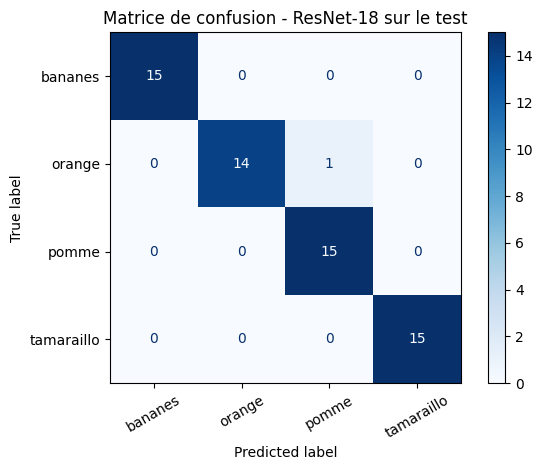

In [ ]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import torch

# Mettre le modèle en mode évaluation
resnet18.eval()

y_true = []
y_pred = []

# Prédictions sur les images de test
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        sorties = resnet18(images)
        predictions = sorties.argmax(dim=1).cpu().tolist()

        y_pred.extend(predictions)
        y_true.extend(labels.tolist())

# Précision globale
precision_test = accuracy_score(y_true, y_pred)

print(f"Précision finale sur le test : {precision_test * 100:.2f}%")
print(f"Images correctement classées : {sum(a == b for a, b in zip(y_true, y_pred))}/{len(y_true)}")

# Rapport détaillé par classe
noms_classes = test_dataset.classes

print("\nRapport de classification :")
print(classification_report(
    y_true,
    y_pred,
    target_names=noms_classes,
    digits=3,
    zero_division=0
))

# Matrice de confusion
matrice = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(noms_classes)))
)

affichage = ConfusionMatrixDisplay(
    confusion_matrix=matrice,
    display_labels=noms_classes
)

affichage.plot(cmap="Blues", values_format="d")
plt.title("Matrice de confusion - ResNet-18 sur le test")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


Nombre d'erreurs : 1


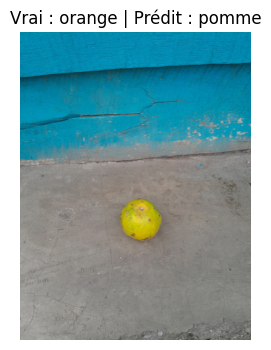

In [ ]:

from PIL import Image
import matplotlib.pyplot as plt
import torch

resnet18.eval()
erreurs = []

with torch.no_grad():
    for images, labels in test_loader:
        images_device = images.to(device)
        sorties = resnet18(images_device)
        predictions = sorties.argmax(dim=1).cpu()

        for i in range(len(labels)):
            vrai = labels[i].item()
            predit = predictions[i].item()

            if vrai != predit:
                chemin, _ = test_dataset.samples[
                    len(erreurs) + sum(1 for _ in [])
                ] if False else (None, None)

                erreurs.append({
                    "vrai": test_dataset.classes[vrai],
                    "predit": test_dataset.classes[predit],
                    "index_vrai": vrai,
                    "index_predit": predit
                })

# Retrouver les fichiers mal classés avec leurs prédictions
erreurs_detaillees = []
index_global = 0

with torch.no_grad():
    for images, labels in test_loader:
        sorties = resnet18(images.to(device))
        predictions = sorties.argmax(dim=1).cpu().tolist()

        for i, vrai in enumerate(labels.tolist()):
            if vrai != predictions[i]:
                chemin = test_dataset.samples[index_global][0]
                erreurs_detaillees.append(
                    (chemin, test_dataset.classes[vrai],
                     test_dataset.classes[predictions[i]])
                )
            index_global += 1

print("Nombre d'erreurs :", len(erreurs_detaillees))

for chemin, vrai, predit in erreurs_detaillees:
    image = Image.open(chemin).convert("RGB")
    plt.figure(figsize=(5, 4))
    plt.imshow(image)
    plt.title(f"Vrai : {vrai} | Prédit : {predit}")
    plt.axis("off")
    plt.show()
